# Titanic Data Analysis

In this project, we analyze the Titanic dataset to explore passenger information and investigate the factors related to survival.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset("titanic")

In [3]:
stdDFAge= np.std(df["age"])
stdDFFare = np.std(df["fare"])

In [4]:
meanAge = np.mean(df["age"])
meanFare = np.mean(df["fare"])

In [5]:
outlierAge = (df["age"] < meanAge - 2 * stdDFAge) | \
             (df["age"] > meanAge + 2 * stdDFAge)

df[outlierAge]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
33,0,2,male,66.00,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
54,0,1,male,65.00,0,1,61.9792,C,First,man,True,B,Cherbourg,no,False
94,0,3,male,59.00,0,0,7.2500,S,Third,man,True,NaN,Southampton,no,True
96,0,1,male,71.00,0,0,34.6542,C,First,man,True,A,Cherbourg,no,True
116,0,3,male,70.50,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True
170,0,1,male,61.00,0,0,33.5000,S,First,man,True,B,Southampton,no,True
232,0,2,male,59.00,0,0,13.5000,S,Second,man,True,NaN,Southampton,no,True
252,0,1,male,62.00,0,0,26.5500,S,First,man,True,C,Southampton,no,True
275,1,1,female,63.00,1,0,77.9583,S,First,woman,False,D,Southampton,yes,False
280,0,3,male,65.00,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True


In [6]:
#df.duplicated().sum()
#df[df.duplicated()]

In [7]:
#df["sex"].value_counts()
#df["embarked"].value_counts()
#df["class"].value_counts()
#df["who"].value_counts()
#df["adult_male"].value_counts()
#df["deck"].value_counts()
#df["embark_town"].value_counts()
#df["alive"].value_counts()
#df["alone"].value_counts()

In [8]:
#df.drop("deck", axis=1, inplace=True)

In [9]:
df[df["survived"] != (df["alive"] == "yes").astype(int)]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone


In [10]:
df[((df["pclass"] == 1) & (df["class"] != "First")) |
   ((df["pclass"] == 2) & (df["class"] != "Second")) |
   ((df["pclass"] == 3) & (df["class"] != "Third"))]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone


In [11]:
df[((df["sex"] == "male") & (df["who"] == "woman")) |
   ((df["sex"] == "female") & (df["who"] == "man"))]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone


In [12]:
df[((df["embarked"] == "S") & (df["embark_town"] != "Southampton")) |
   ((df["embarked"] == "C") & (df["embark_town"] != "Cherbourg")) |
   ((df["embarked"] == "Q") & (df["embark_town"] != "Queenstown"))]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone


In [13]:
df.drop(["alive", "pclass", "embarked"], axis=1, inplace=True)

In [14]:
#df.shape
#df.isnull().sum()

In [15]:
df["survived"].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

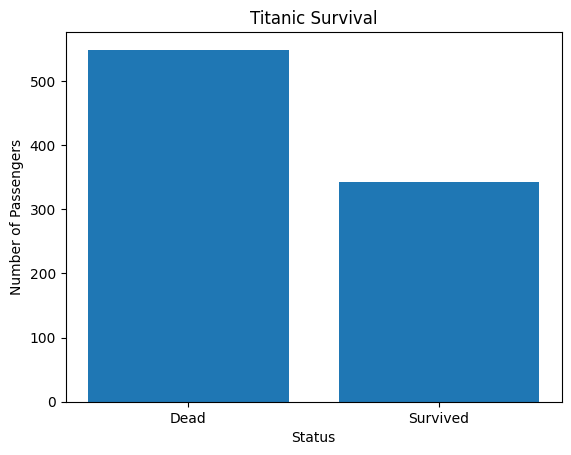

In [16]:
survival = df["survived"].value_counts()

plt.bar(["Dead", "Survived"], survival)
plt.title("Titanic Survival")
plt.xlabel("Status")
plt.ylabel("Number of Passengers")
plt.show()

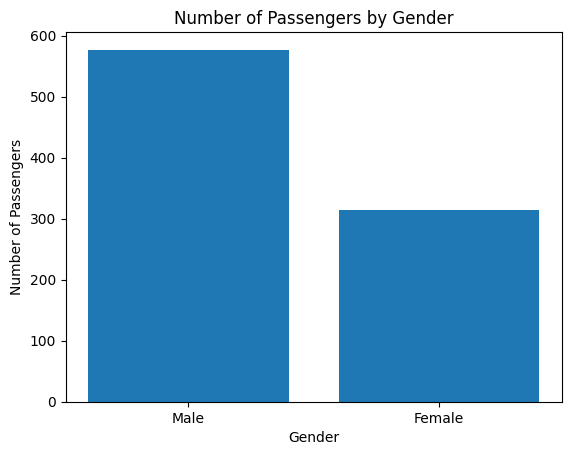

In [17]:
sexCount = df["sex"].value_counts()

plt.bar(["Male", "Female"], [sexCount["male"], sexCount["female"]])
plt.title("Number of Passengers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

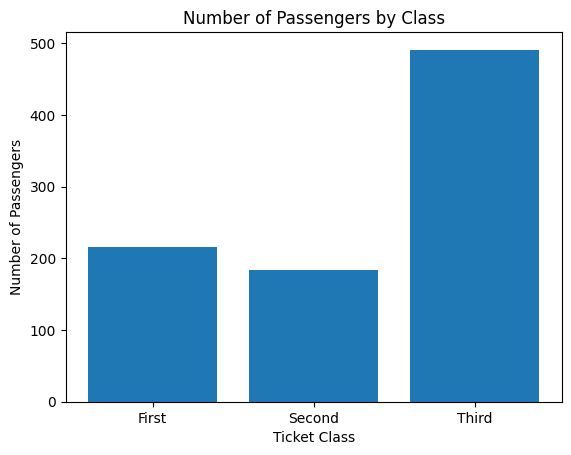

In [18]:
classCount = df["class"].value_counts()

plt.bar(["First", "Second", "Third"], [
    classCount["First"],
    classCount["Second"],
    classCount["Third"]
])

plt.title("Number of Passengers by Class")
plt.xlabel("Ticket Class")
plt.ylabel("Number of Passengers")
plt.show()

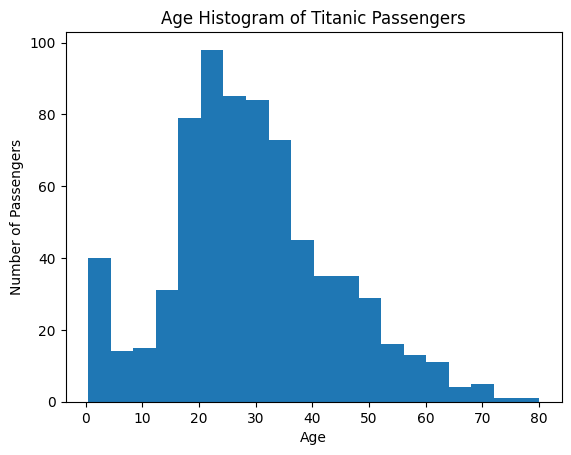

In [19]:
#df["age"].mean()
#df["age"].min()
#df["age"].max()

plt.hist(df["age"], bins=20)

plt.title("Age Histogram of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

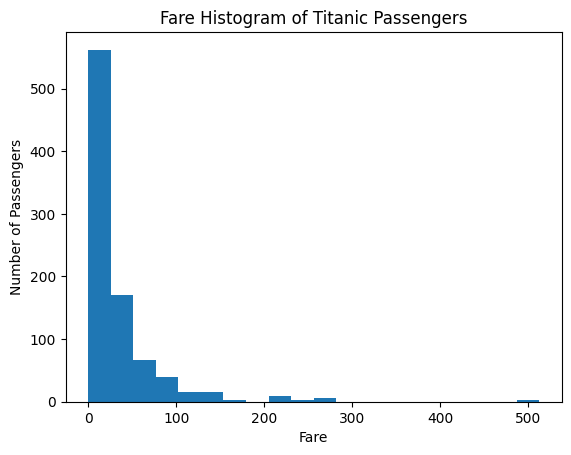

In [20]:
# df["fare"].mean()
# df["fare"].min()
# df["fare"].max()

plt.hist(df["fare"], bins=20)

plt.title("Fare Histogram of Titanic Passengers")
plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.show()

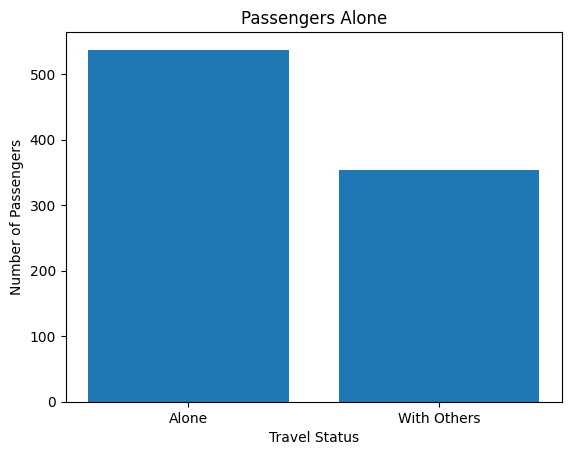

In [21]:
# df["alone"].value_counts()

aloneCount = df["alone"].value_counts()

plt.bar(["Alone", "With Others"], [
    aloneCount[True],
    aloneCount[False]
])

plt.title("Passengers Alone")
plt.xlabel("Travel Status")
plt.ylabel("Number of Passengers")
plt.show()

In [22]:
df["sibsp"].value_counts()

sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

In [23]:
df["parch"].value_counts()

parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

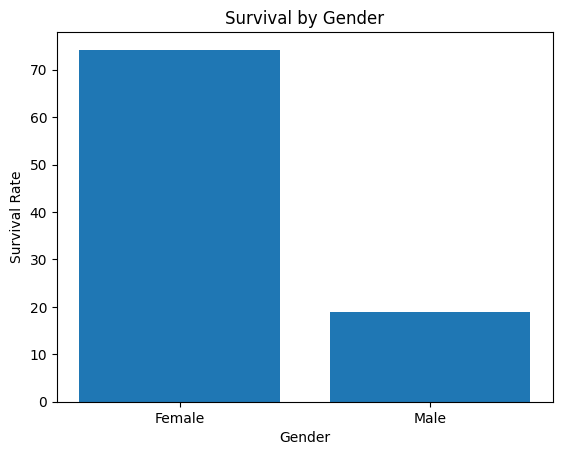

In [24]:
female = df[df["sex"] == "female"]["survived"].mean() * 100
male = df[df["sex"] == "male"]["survived"].mean() * 100

plt.bar(["Female", "Male"], [female, male])
plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.show()

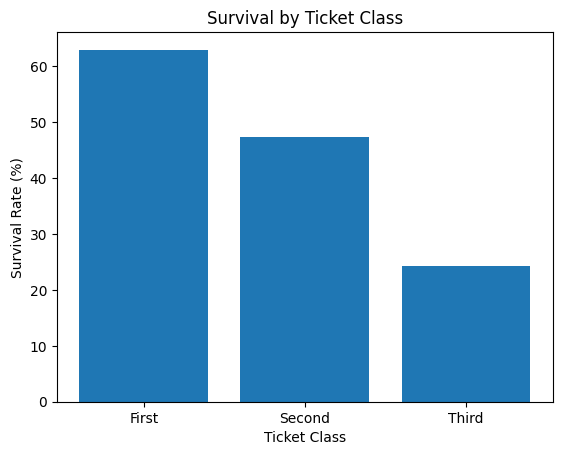

In [25]:
first = df[df["class"] == "First"]["survived"].mean() * 100
second = df[df["class"] == "Second"]["survived"].mean() * 100
third = df[df["class"] == "Third"]["survived"].mean() * 100

plt.bar(["First", "Second", "Third"], [first, second, third])
plt.title("Survival by Ticket Class")
plt.xlabel("Ticket Class")
plt.ylabel("Survival Rate (%)")
plt.show()

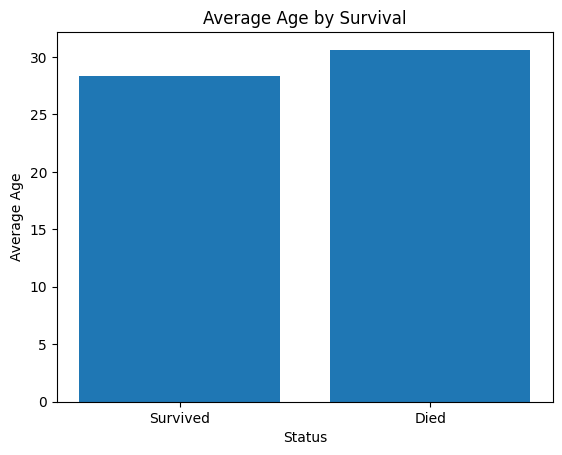

In [26]:
survived = df[df["survived"] == 1]["age"].mean()
died = df[df["survived"] == 0]["age"].mean()

plt.bar(["Survived", "Died"], [survived, died])
plt.title("Average Age by Survival")
plt.xlabel("Status")
plt.ylabel("Average Age")
plt.show()

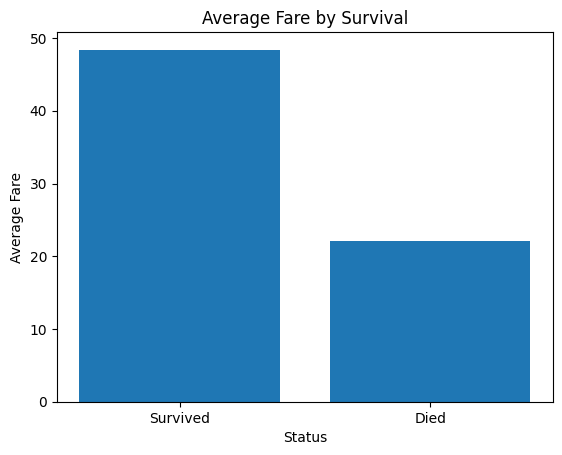

In [27]:
survived = df[df["survived"] == 1]["fare"].mean()
died = df[df["survived"] == 0]["fare"].mean()

plt.bar(["Survived", "Died"], [survived, died])
plt.title("Average Fare by Survival")
plt.xlabel("Status")
plt.ylabel("Average Fare")
plt.show()

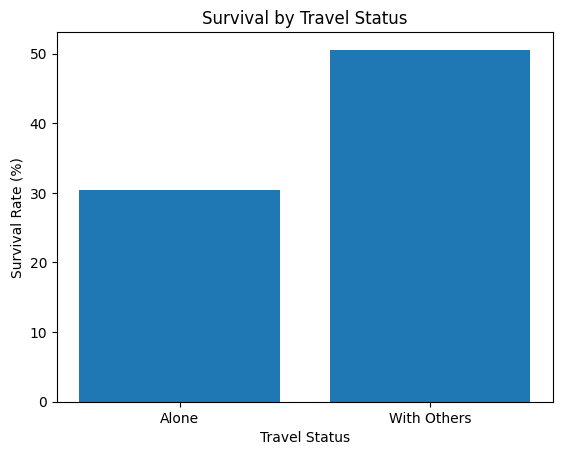

In [28]:
alone = df[df["alone"] == True]["survived"].mean() * 100
notAlone = df[df["alone"] == False]["survived"].mean() * 100

plt.bar(["Alone", "With Others"], [alone, notAlone])
plt.title("Survival by Travel Status")
plt.xlabel("Travel Status")
plt.ylabel("Survival Rate (%)")
plt.show()

In [29]:
for i in range(9):
    rate = df[df["sibsp"] == i]["survived"].mean() * 100
    print(i, rate)

0 34.53947368421053
1 53.588516746411486
2 46.42857142857143
3 25.0
4 16.666666666666664
5 0.0
6 nan
7 nan
8 0.0


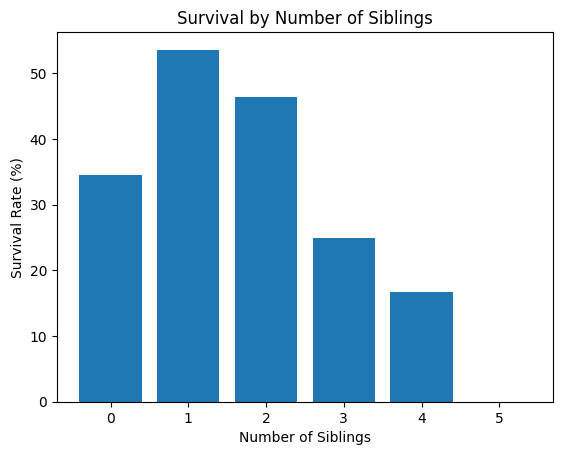

In [30]:
x = [0, 1, 2, 3, 4, 5]
y = []

for i in x:
    rate = df[df["sibsp"] == i]["survived"].mean() * 100
    y.append(rate)

plt.bar(x, y)
plt.title("Survival by Number of Siblings")
plt.xlabel("Number of Siblings")
plt.ylabel("Survival Rate (%)")
plt.show()

In [31]:
for i in range(7):
    rate = df[df["parch"] == i]["survived"].mean() * 100
    print(i, rate)

0 34.365781710914455
1 55.08474576271186
2 50.0
3 60.0
4 0.0
5 20.0
6 0.0


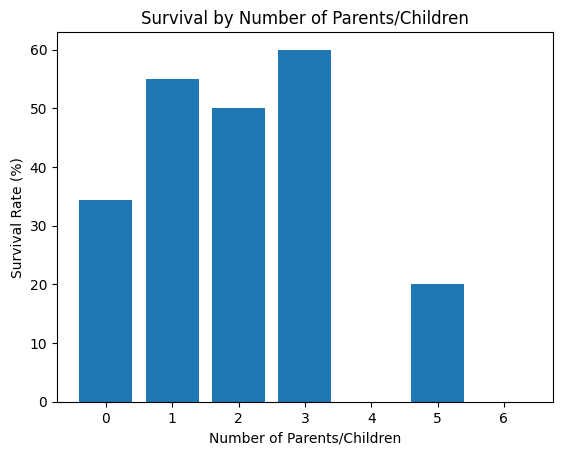

In [32]:
x = [0, 1, 2, 3, 4, 5, 6]
y = []

for i in x:
    rate = df[df["parch"] == i]["survived"].mean() * 100
    y.append(rate)

plt.bar(x, y)
plt.title("Survival by Number of Parents/Children")
plt.xlabel("Number of Parents/Children")
plt.ylabel("Survival Rate (%)")
plt.show()